# KT-01 — MLP với PyTorch: dự đoán khách hàng rời bỏ 

In [22]:
import os, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import average_precision_score
from xgboost import XGBClassifier

from pathlib import Path
if Path.cwd().name == "notebooks": os.chdir(Path.cwd().parent)
os.makedirs("reports", exist_ok=True); os.makedirs("models", exist_ok=True)
print("Thư mục làm việc :", os.getcwd())
print("Báo cáo lưu tại   :", os.path.abspath("reports"))
print("Model lưu tại     :", os.path.abspath("models"))

EPOCHS = int(os.environ.get("EPOCHS", 50))     # số epoch tối đa
PATIENCE = 8                                   # early stopping
def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

Thư mục làm việc : d:\TT_ML\Học sâu\KT-01-MLP-PyTorch_Linh
Báo cáo lưu tại   : d:\TT_ML\Học sâu\KT-01-MLP-PyTorch_Linh\reports
Model lưu tại     : d:\TT_ML\Học sâu\KT-01-MLP-PyTorch_Linh\models
PyTorch 2.14.1+cpu | device: cpu


## 1. Tiền xử lý (Bước 1)

Mạng nơ-ron chỉ nhận số và rất nhạy với thang đo, nên: ép kiểu `TotalCharges`, bỏ `customerID`, chuẩn hoá cột số, one-hot cột chữ.

In [23]:
path = next(p for p in ["D:\TT_ML\Học sâu\KT-01-MLP-PyTorch_Linh\data\WA_Fn-UseC_-Telco-Customer-Churn.csv",
                        "WA_Fn-UseC_-Telco-Customer-Churn.csv"] if os.path.exists(p))
df = pd.read_csv(path)
print(df.shape, "| tỉ lệ churn:", (df["Churn"] == "Yes").mean().round(3))

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)  # 11 dòng rỗng
df = df.drop(columns="customerID")
y = (df.pop("Churn") == "Yes").astype(int).values

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols]

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

# 60 / 20 / 20, giữ nguyên tỉ lệ churn
X_tmp, X_test, y_tmp, y_test = train_test_split(df, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42)

X_train = pre.fit_transform(X_train).astype("float32")
X_val   = pre.transform(X_val).astype("float32")
X_test  = pre.transform(X_test).astype("float32")
n_features = X_train.shape[1]
print("train/val/test:", X_train.shape, X_val.shape, X_test.shape, "| n_features =", n_features)

(7043, 21) | tỉ lệ churn: 0.265
train/val/test: (4225, 46) (1409, 46) (1409, 46) | n_features = 46


<>:1: SyntaxWarning: invalid escape sequence '\T'
<>:1: SyntaxWarning: invalid escape sequence '\T'
C:\Users\lenovo\AppData\Local\Temp\ipykernel_31720\2248428104.py:1: SyntaxWarning: invalid escape sequence '\T'
  path = next(p for p in ["D:\TT_ML\Học sâu\KT-01-MLP-PyTorch_Linh\data\WA_Fn-UseC_-Telco-Customer-Churn.csv",


## 2. Dataset + DataLoader (Bước 2)

`Dataset` trả về **1 mẫu**; `DataLoader` gom thành batch và xáo trộn. Nhãn cần `unsqueeze(1)` để có shape `(N, 1)` khớp output của model.

In [24]:
class ChurnDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

train_loader = DataLoader(ChurnDataset(X_train, y_train), batch_size=32, shuffle=True, drop_last=True)
val_loader   = DataLoader(ChurnDataset(X_val, y_val), batch_size=256)
test_loader  = DataLoader(ChurnDataset(X_test, y_test), batch_size=256)

xb, yb = next(iter(train_loader))
print("1 batch:", xb.shape, yb.shape)   # [64, n_features] và [64, 1]

1 batch: torch.Size([32, 46]) torch.Size([32, 1])


## 3. Model (Bước 3)

Output là **logit** (số thực bất kỳ), **không có sigmoid** trong model. `BCEWithLogitsLoss` đã gộp sigmoid + loss thành một công thức ổn định số học (tránh log(0) → NaN). Khi cần xác suất thì gọi `torch.sigmoid(logits)` lúc dự đoán.

In [25]:
class MLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64),         nn.BatchNorm1d(64),  nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 1),            # logit, KHÔNG sigmoid
        )
    def forward(self, x): return self.net(x)

print(MLP(n_features))
n_params = sum(p.numel() for p in MLP(n_features).parameters() if p.requires_grad)
print("Số tham số huấn luyện được:", f"{n_params:,}")

MLP(
  (net): Sequential(
    (0): Linear(in_features=46, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)
Số tham số huấn luyện được: 14,721


## 4. Vòng lặp huấn luyện (Bước 4)

Bốn dòng hay quên:

| Dòng | Thiếu thì sao |
|---|---|
| `optimizer.zero_grad()` | Gradient **cộng dồn** qua các batch → cập nhật sai hướng |
| `model.train()` | Dropout/BatchNorm không ở chế độ huấn luyện |
| `model.eval()` | Dropout vẫn bật lúc đánh giá → điểm dao động ngẫu nhiên |
| `torch.no_grad()` | Tốn RAM, chậm |

Hàm `train()` có các "công tắc" `zero_grad` và `use_eval` để làm 2 thí nghiệm cố tình sai ở Phần 5.

`pos_weight = (số lớp 0) / (số lớp 1)` làm sai sót trên khách churn bị phạt nặng hơn, bù cho việc nhãn lệch (26,5%).

In [26]:
pos_weight = torch.tensor([(y_train == 0).sum() / (y_train == 1).sum()], dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print("pos_weight =", pos_weight.item())

def evaluate(model, loader, use_eval=True):
    model.eval() if use_eval else model.train()
    probs, ys, total = [], [], 0.0
    with torch.no_grad():                                  # ④ không tính gradient
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total += criterion(logits, yb).item() * len(yb)
            probs.append(torch.sigmoid(logits).cpu()); ys.append(yb.cpu())
    probs = np.nan_to_num(torch.cat(probs).numpy().ravel(), nan=0.5)   # phòng trường hợp loss nổ NaN
    ys = torch.cat(ys).numpy().ravel()
    return total / len(ys), average_precision_score(ys, probs)

def train(model, optimizer, epochs=EPOCHS, zero_grad=True, use_eval=True,
          patience=None, ckpt="models/best.pt", verbose=False):
    hist = {"train_loss": [], "val_loss": [], "val_prauc": []}
    best, wait = -1.0, 0
    for epoch in range(epochs):
        model.train()                                      # bật Dropout/BatchNorm train
        running = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            if zero_grad: optimizer.zero_grad()            # xoá gradient batch trước
            loss = criterion(model(xb), yb)                # forward + loss
            loss.backward()                                # backprop
            optimizer.step()                               # cập nhật trọng số
            running += loss.item() * len(yb)
        vl, vp = evaluate(model, val_loader, use_eval)     # eval (trừ khi cố tình bỏ)
        hist["train_loss"].append(running / len(train_loader.dataset))
        hist["val_loss"].append(vl); hist["val_prauc"].append(vp)
        if verbose:
            print(f"epoch {epoch+1:3d} | train {hist['train_loss'][-1]:.4f} | val {vl:.4f} | PR-AUC {vp:.4f}")
        if patience is not None:                           # early stopping (Bước 8)
            if vp > best:
                best, wait = vp, 0; torch.save(model.state_dict(), ckpt)
            else:
                wait += 1
                if wait >= patience: break
    return hist

def fresh(seed=0, opt="adamw", lr=1e-3):
    set_seed(seed)
    m = MLP(n_features).to(device)
    makers = {
        "sgd":   lambda p: torch.optim.SGD(p, lr=1e-2, momentum=0.9),
        "adam":  lambda p: torch.optim.Adam(p, lr=lr),
        "adamw": lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=1e-4),
    }
    return m, makers[opt](m.parameters())

# Chạy thử vòng lặp chuẩn (có in từng epoch)
model, optimizer = fresh()
hist = train(model, optimizer, epochs=min(EPOCHS, 10), verbose=True)

pos_weight = 2.768956184387207


epoch   1 | train 0.7769 | val 0.7419 | PR-AUC 0.6466
epoch   2 | train 0.7302 | val 0.7455 | PR-AUC 0.6418
epoch   3 | train 0.7190 | val 0.7420 | PR-AUC 0.6429
epoch   4 | train 0.7150 | val 0.7394 | PR-AUC 0.6431
epoch   5 | train 0.7153 | val 0.7405 | PR-AUC 0.6397
epoch   6 | train 0.7101 | val 0.7406 | PR-AUC 0.6407
epoch   7 | train 0.7072 | val 0.7419 | PR-AUC 0.6386
epoch   8 | train 0.6969 | val 0.7420 | PR-AUC 0.6386
epoch   9 | train 0.6958 | val 0.7456 | PR-AUC 0.6356
epoch  10 | train 0.6866 | val 0.7458 | PR-AUC 0.6403


## 5. Hai thí nghiệm cố tình sai (Bước 5, 6)

### Thí nghiệm 1 — bỏ `optimizer.zero_grad()`
**Giả thuyết:** gradient cộng dồn qua mọi batch nên bước cập nhật đi theo *tổng* gradient của quá khứ → loss không giảm đều, có thể dao động hoặc nổ.

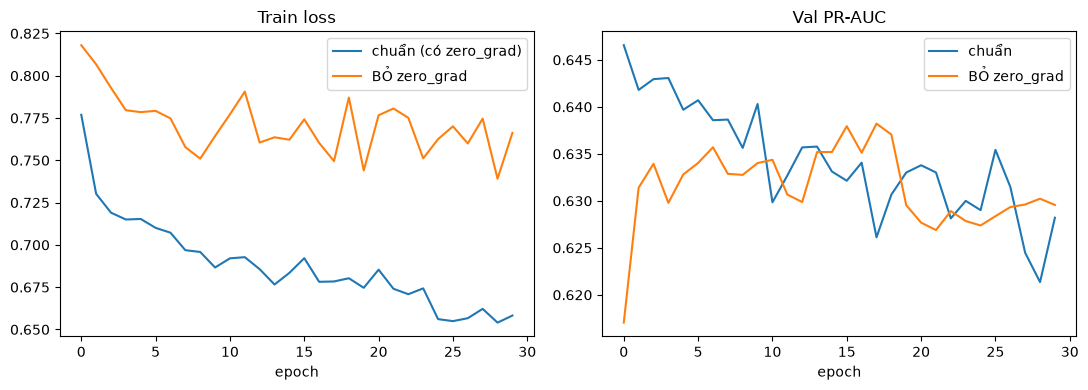

Cuối cùng  | chuẩn: loss=0.6582, PR-AUC=0.6282
           | bỏ zg: loss=0.7662, PR-AUC=0.6296


In [27]:
t0 = time.time()
m, o = fresh(); h_ok   = train(m, o, epochs=30)
m, o = fresh(); h_nozg = train(m, o, epochs=30, zero_grad=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h_ok["train_loss"], label="chuẩn (có zero_grad)")
ax[0].plot(h_nozg["train_loss"], label="BỎ zero_grad")
ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h_ok["val_prauc"], label="chuẩn"); ax[1].plot(h_nozg["val_prauc"], label="BỎ zero_grad")
ax[1].set_title("Val PR-AUC"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("reports/exp1_no_zero_grad.png", dpi=150); plt.show()

print(f"Cuối cùng  | chuẩn: loss={h_ok['train_loss'][-1]:.4f}, PR-AUC={h_ok['val_prauc'][-1]:.4f}")
print(f"           | bỏ zg: loss={h_nozg['train_loss'][-1]:.4f}, PR-AUC={h_nozg['val_prauc'][-1]:.4f}")

### Thí nghiệm 2 — bỏ `model.eval()` khi đánh giá
**Giả thuyết:** Dropout vẫn bật nên cùng một model, cùng dữ liệu nhưng mỗi lần đánh giá ra một điểm khác nhau. Ta đo bằng cách đánh giá 10 lần liên tiếp.

In [28]:
m, o = fresh(); train(m, o, epochs=15)    

import copy
state = copy.deepcopy(m.state_dict())
score_eval  = [evaluate(m, val_loader, use_eval=True)[1] for _ in range(10)]
score_train = []
for _ in range(10):
    m.load_state_dict(state)
    score_train.append(evaluate(m, val_loader, use_eval=False)[1])

print("Có model.eval() :", np.round(score_eval, 4), "| std =", np.std(score_eval).round(5))
print("BỎ model.eval() :", np.round(score_train, 4), "| std =", np.std(score_train).round(5))
print(f"Khoảng dao động khi bỏ eval: {max(score_train)-min(score_train):.4f} PR-AUC")

Có model.eval() : [0.6331 0.6331 0.6331 0.6331 0.6331 0.6331 0.6331 0.6331 0.6331 0.6331] | std = 0.0
BỎ model.eval() : [0.6168 0.6243 0.6217 0.6183 0.6355 0.6261 0.6195 0.6164 0.6147 0.6008] | std = 0.00848
Khoảng dao động khi bỏ eval: 0.0347 PR-AUC


## 6. Learning curve (Bước 7) + Early stopping (Bước 8)

Train với early stopping: theo dõi val PR-AUC, lưu checkpoint tốt nhất, dừng khi `PATIENCE` epoch liền không cải thiện.

Dừng sau 9 epoch | epoch tốt nhất: 1 | thời gian: 1.8s


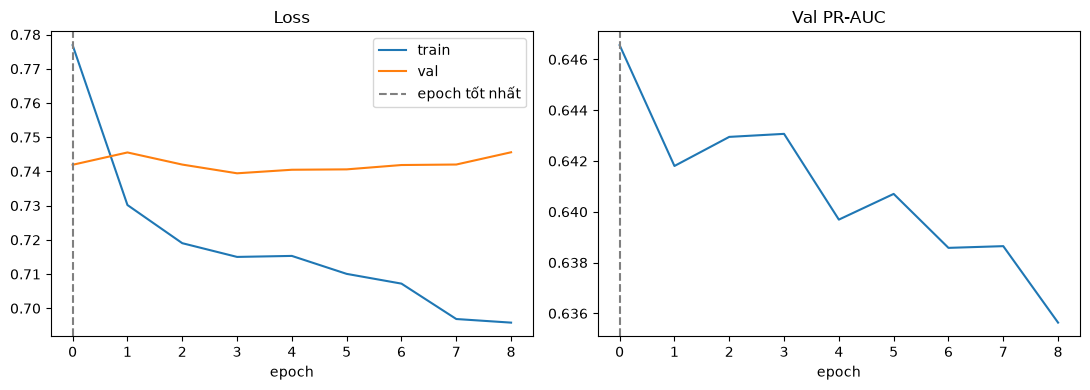

In [29]:
model, optimizer = fresh(opt="adamw")
t0 = time.time()
hist = train(model, optimizer, epochs=EPOCHS, patience=PATIENCE, ckpt="models/best.pt")
t_mlp = time.time() - t0
best_ep = int(np.argmax(hist["val_prauc"])) + 1
print(f"Dừng sau {len(hist['val_prauc'])} epoch | epoch tốt nhất: {best_ep} | thời gian: {t_mlp:.1f}s")

model.load_state_dict(torch.load("models/best.pt", map_location=device))   # nạp lại bản tốt nhất

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="val")
ax[0].axvline(best_ep - 1, ls="--", c="gray", label="epoch tốt nhất")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist["val_prauc"]); ax[1].axvline(best_ep - 1, ls="--", c="gray")
ax[1].set_title("Val PR-AUC"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig("reports/learning_curve.png", dpi=150); plt.show()

## 7. So sánh 3 optimizer (Bước 9)

Chạy mỗi optimizer với 3 seed để biết chênh lệch có vượt quá nhiễu hay không.

           PR_AUC_mean  PR_AUC_std  epochs  seconds
optimizer                                          
ADAM            0.6416      0.0044    11.0   3.1496
ADAMW           0.6417      0.0043    11.0   2.3849
SGD             0.6414      0.0019    12.0   1.8430


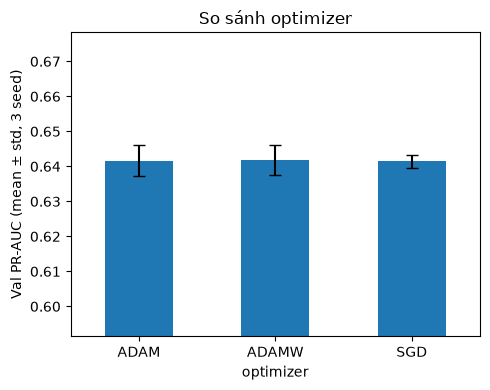

In [30]:
rows = []
for name in ["sgd", "adam", "adamw"]:
    for seed in range(3):
        m, o = fresh(seed=seed, opt=name)
        t0 = time.time()
        h = train(m, o, epochs=EPOCHS, patience=PATIENCE, ckpt=f"models/{name}_{seed}.pt")
        dt = time.time() - t0
        m.load_state_dict(torch.load(f"models/{name}_{seed}.pt", map_location=device))
        rows.append({"optimizer": name.upper(), "seed": seed, "val_PR_AUC": evaluate(m, val_loader)[1],
                     "epochs": len(h["val_prauc"]), "seconds": dt})
opt_df = pd.DataFrame(rows)
opt_summary = opt_df.groupby("optimizer").agg(PR_AUC_mean=("val_PR_AUC", "mean"), PR_AUC_std=("val_PR_AUC", "std"),
                                              epochs=("epochs", "mean"), seconds=("seconds", "mean")).round(4)
print(opt_summary)

ax = opt_summary["PR_AUC_mean"].plot.bar(yerr=opt_summary["PR_AUC_std"], capsize=4, figsize=(5, 4), rot=0)
ax.set_ylabel("Val PR-AUC (mean ± std, 3 seed)"); ax.set_title("So sánh optimizer")
ymin = opt_summary["PR_AUC_mean"].min() - 0.05; ax.set_ylim(max(ymin, 0), None)
plt.tight_layout(); plt.savefig("reports/optimizer_comparison.png", dpi=150); plt.show()

## 8. So sánh với XGBoost (Bước 10)

Cùng dữ liệu, cùng tập test. So sánh PR-AUC, thời gian train và công sức.

In [31]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
t0 = time.time()
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, scale_pos_weight=spw,
                    eval_metric="aucpr", random_state=0)
xgb.fit(X_train, y_train)
t_xgb = time.time() - t0
pr_xgb = average_precision_score(y_test, xgb.predict_proba(X_test)[:, 1])

model.load_state_dict(torch.load("models/best.pt", map_location=device))
_, pr_mlp = evaluate(model, test_loader)

cmp_df = pd.DataFrame({
    "model": ["MLP (PyTorch)", "XGBoost"],
    "test_PR_AUC": [pr_mlp, pr_xgb],
    "train_seconds": [t_mlp, t_xgb],
    "so_sieu_tham_so_chinh": ["~8 (lr, batch, dropout x2, wd, patience, kiến trúc...)", "~3 (n_estimators, depth, lr)"],
}).round(4)
cmp_df.to_csv("reports/vs_xgboost.csv", index=False)
display(cmp_df) if "display" in globals() else print(cmp_df)

gap = pr_xgb - pr_mlp
print(f"\nChênh lệch PR-AUC (XGBoost - MLP) = {gap:+.4f}")
print("✔ Đạt tiêu chí 'không thua XGBoost quá 0,03'" if gap <= 0.03 else "✘ MLP thua XGBoost quá 0,03 — thử tinh chỉnh thêm")
print(f"XGBoost train nhanh hơn ~{t_mlp / max(t_xgb, 1e-9):.1f} lần")

           model  test_PR_AUC  train_seconds  \
0  MLP (PyTorch)       0.6367         1.8347   
1        XGBoost       0.6474         0.1657   

                               so_sieu_tham_so_chinh  
0  ~8 (lr, batch, dropout x2, wd, patience, kiến ...  
1                       ~3 (n_estimators, depth, lr)  

Chênh lệch PR-AUC (XGBoost - MLP) = +0.0107
✔ Đạt tiêu chí 'không thua XGBoost quá 0,03'
XGBoost train nhanh hơn ~11.1 lần


## 9. Lưu/nạp model (Bước 11) và CPU vs GPU (Bước 12)

Chỉ lưu `state_dict` (trọng số). `torch.save(model)` lưu cả class nên vỡ khi bạn đổi cấu trúc code.

In [32]:
torch.save(model.state_dict(), "models/best.pt")

m2 = MLP(n_features).to(device)
m2.load_state_dict(torch.load("models/best.pt", map_location=device))
m2.eval()

r1, r2 = evaluate(model, test_loader), evaluate(m2, test_loader)
print("Model gốc :", r1)
print("Model nạp :", r2)
assert np.allclose(r1, r2), "Kết quả không khớp!"
print("✔ Nạp lại cho đúng kết quả y hệt")

Model gốc : (0.723703157571802, 0.6366894090209625)
Model nạp : (0.723703157571802, 0.6366894090209625)
✔ Nạp lại cho đúng kết quả y hệt


In [33]:
def time_train(dev, epochs=10):
    global device
    old, device = device, torch.device(dev)
    global pos_weight, criterion
    pos_weight = pos_weight.to(device); criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    m, o = fresh()
    if dev == "cuda": torch.cuda.synchronize()
    t0 = time.time(); train(m, o, epochs=epochs)
    if dev == "cuda": torch.cuda.synchronize()
    dt = time.time() - t0
    device = old
    pos_weight = pos_weight.to(device); criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    return dt

timing = {"cpu": time_train("cpu")}
if torch.cuda.is_available(): timing["cuda"] = time_train("cuda")
print({k: f"{v:.1f}s / 10 epoch" for k, v in timing.items()})
if "cuda" not in timing:
    print("Không có GPU. Có thể chạy trên Google Colab (Runtime > Change runtime type > GPU) để so sánh.")

{'cpu': '3.5s / 10 epoch'}
Không có GPU. Có thể chạy trên Google Colab (Runtime > Change runtime type > GPU) để so sánh.
